In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,GroupKFold, cross_validate, cross_val_score,cross_val_predict, GridSearchCV)
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler,PolynomialFeatures, FunctionTransformer,LabelEncoder)
from sklearn.feature_selection import SequentialFeatureSelector,VarianceThreshold
from sklearn.decomposition import FactorAnalysis
from sklearn.linear_model import (LinearRegression, LogisticRegression,ElasticNet, Ridge, LassoCV)
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor,  HistGradientBoostingClassifier)
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,  accuracy_score, precision_score, recall_score,  f1_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [3]:
warnings.filterwarnings("ignore")
SEED = 42
REG, CLF = "regression", "classification"
SKEWED = ["infant deaths", "under-five deaths", "Measles", "Population",
          "GDP", "percentage expenditure", "HIV/AIDS"]

In [4]:
df=pd.read_csv("Life Expectancy Data.csv")
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [5]:
df.isnull().sum()

Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
 BMI                                34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
 HIV/AIDS                            0
GDP                                448
Population                         652
 thinness  1-19 years               34
 thinness 5-9 years                 34
Income composition of resources    167
Schooling                          163
dtype: int64

In [6]:
df.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [8]:
df.shape

(2938, 22)

In [9]:
df.columns

Index(['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure',
       'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income composition of resources', 'Schooling'],
      dtype='object')

In [10]:
# Remove rows with any missing values
df_cleaned = df.dropna()
print(f"Original DataFrame shape: {df.shape}")
print(f"DataFrame shape after removing missing values: {df_cleaned.shape}")
print("Missing values after removal:")
print(df_cleaned.isnull().sum().sum())

Original DataFrame shape: (2938, 22)
DataFrame shape after removing missing values: (1649, 22)
Missing values after removal:
0


In [11]:
df_cleaned.columns = df_cleaned.columns.str.strip().str.replace(' ', '_').str.replace('-', '_').str.replace('/', '_')

In [12]:
X = df_cleaned.drop('Life_expectancy', axis=1)
y = df_cleaned['Life_expectancy']
display(X.head())
display(y.head())

,Country,Year,Status,Adult_Mortality,infant_deaths,Alcohol,percentage_expenditure,Hepatitis_B,Measles,BMI,...,Polio,Total_expenditure,Diphtheria,HIV_AIDS,GDP,Population,thinness__1_19_years,thinness_5_9_years,Income_composition_of_resources,Schooling
0,Afghanistan,2015,Developing,263.0,62,0.01,71.279624,65.0,1154,19.1,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,271.0,64,0.01,73.523582,62.0,492,18.6,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,268.0,66,0.01,73.219243,64.0,430,18.1,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,272.0,69,0.01,78.184215,67.0,2787,17.6,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,275.0,71,0.01,7.097109,68.0,3013,17.2,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


0    65.0
1    59.9
2    59.9
3    59.5
4    59.2
Name: Life_expectancy, dtype: float64

In [13]:
categorical_cols = X.select_dtypes(include='object').columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

In [14]:
scaler = StandardScaler()
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

# Perform train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

print(f"Number of instances in the cleaned dataset: {df_cleaned.shape[0]}")
print(f"Number of features in the processed dataset: {X.shape[1]}")
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

Number of instances in the cleaned dataset: 1649
Number of features in the processed dataset: 21
Shape of X_train: (1319, 21)
Shape of X_test: (330, 21)
Shape of y_train: (1319,)
Shape of y_test: (330,)


In [15]:
# Apply Low Variance Filter
sel = VarianceThreshold(threshold=(.8 * (1 - .8)))
sel.fit(X_train)
X_train_low_variance = X_train.loc[:, sel.get_support()]

print("Features retained by Low Variance Filter:")
print(list(X_train_low_variance.columns))

Features retained by Low Variance Filter:
['Country', 'Year', 'Adult_Mortality', 'infant_deaths', 'Alcohol', 'percentage_expenditure', 'Hepatitis_B', 'Measles', 'BMI', 'under_five_deaths', 'Polio', 'Total_expenditure', 'Diphtheria', 'HIV_AIDS', 'GDP', 'Population', 'thinness__1_19_years', 'thinness_5_9_years', 'Income_composition_of_resources', 'Schooling']


In [16]:
# Apply High Correlation Filter
corr_matrix = X_train.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.90)] # Threshold set to 0.90
X_train_high_correlation = X_train.drop(columns=to_drop)

print("Features retained by High Correlation Filter:")
print(list(X_train_high_correlation.columns))

Features retained by High Correlation Filter:
['Country', 'Year', 'Status', 'Adult_Mortality', 'infant_deaths', 'Alcohol', 'percentage_expenditure', 'Hepatitis_B', 'Measles', 'BMI', 'Polio', 'Total_expenditure', 'Diphtheria', 'HIV_AIDS', 'Population', 'thinness__1_19_years', 'Income_composition_of_resources', 'Schooling']


In [17]:
# Apply Factor Analysis
n_components = min(10, X_train.shape[1]) # Example: Using 10 components or fewer if features are less
fa = FactorAnalysis(n_components=n_components, random_state=SEED)
X_train_factor_analysis = fa.fit_transform(X_train)

print(f"Shape of data after Factor Analysis: {X_train_factor_analysis.shape}")
print(f"Number of components retained: {n_components}")

Shape of data after Factor Analysis: (1319, 10)
Number of components retained: 10


In [18]:
# Apply Backward Feature Elimination
estimator = LinearRegression()
sfs_backward = SequentialFeatureSelector(estimator, n_features_to_select=10, direction='backward', cv=2, n_jobs=-1)
sfs_backward.fit(X_train, y_train)
X_train_bfe = X_train.loc[:, sfs_backward.get_support()]

print("Features retained by Backward Feature Elimination:")
print(list(X_train_bfe.columns))

Features retained by Backward Feature Elimination:
['Year', 'Adult_Mortality', 'infant_deaths', 'percentage_expenditure', 'BMI', 'under_five_deaths', 'Diphtheria', 'HIV_AIDS', 'Income_composition_of_resources', 'Schooling']


In [19]:
# Apply Forward Feature Selection
estimator = LinearRegression()
sfs_forward = SequentialFeatureSelector(estimator, n_features_to_select=10, direction='forward', cv=2, n_jobs=-1)
sfs_forward.fit(X_train, y_train)
X_train_ffs = X_train.loc[:, sfs_forward.get_support()]

print("Features retained by Forward Feature Selection:")
print(list(X_train_ffs.columns))

Features retained by Forward Feature Selection:
['Year', 'Adult_Mortality', 'Alcohol', 'percentage_expenditure', 'BMI', 'Diphtheria', 'HIV_AIDS', 'thinness__1_19_years', 'Income_composition_of_resources', 'Schooling']


## Model Building: Linear Regression with Gradient Descent

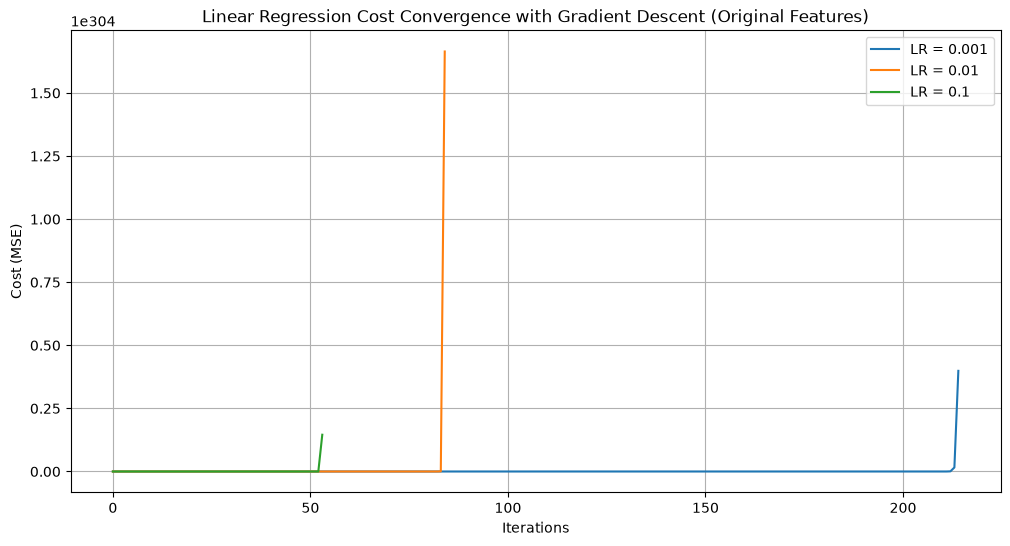

In [20]:
def compute_cost_linear_regression(X, y, weights, bias):
    m = len(y)
    predictions = X.dot(weights) + bias
    cost = (1/(2*m)) * np.sum(np.square(predictions - y))
    return cost

def gradient_descent_linear_regression(X, y, learning_rate, iterations):
    m, n = X.shape
    weights = np.zeros(n)
    bias = 0
    cost_history = []

    for i in range(iterations):
        predictions = X.dot(weights) + bias
        errors = predictions - y
        weights = weights - (learning_rate / m) * X.T.dot(errors)
        bias = bias - (learning_rate / m) * np.sum(errors)
        cost = compute_cost_linear_regression(X, y, weights, bias)
        cost_history.append(cost)
    return weights, bias, cost_history

X_train_fa_df = pd.DataFrame(X_train_factor_analysis, columns=[f'PC{i+1}' for i in range(X_train_factor_analysis.shape[1])], index=X_train.index)
learning_rates = [0.001, 0.01, 0.1]
iterations = 1000

plt.figure(figsize=(12, 6))
for lr in learning_rates:
    _, _, cost_history = gradient_descent_linear_regression(X_train.values, y_train.values, lr, iterations)
    plt.plot(range(iterations), cost_history, label=f'LR = {lr}')

plt.title('Linear Regression Cost Convergence with Gradient Descent (Original Features)')
plt.xlabel('Iterations')
plt.ylabel('Cost (MSE)')
plt.legend()
plt.grid(True)
plt.show()

### Linear Regression with various Feature Sets (using scikit-learn for simplified evaluation)

In [34]:
def train_and_evaluate_linear_regression(X_train_data, X_test_data, y_train_data, y_test_data, feature_set_name):
    model = LinearRegression()
    model.fit(X_train_data, y_train_data)
    y_pred = model.predict(X_test_data)

    mse = mean_squared_error(y_test_data, y_pred)
    r2 = r2_score(y_test_data, y_pred)

    print(f"--- Linear Regression with {feature_set_name} ---")
    print(f"Mean Squared Error: {mse:.4f}")
    print(f"R-squared: {r2:.4f}\n")
    return mse, r2

# Evaluate models with different feature sets
mse_original, r2_original = train_and_evaluate_linear_regression(X_train, X_test, y_train, y_test, "Original Features")

--- Linear Regression with Original Features ---
Mean Squared Error: 13.0247
R-squared: 0.8166



In [35]:
mse_low_variance, r2_low_variance = train_and_evaluate_linear_regression(X_train_low_variance, X_test[X_train_low_variance.columns], y_train, y_test, "Low Variance Filter Features")

--- Linear Regression with Low Variance Filter Features ---
Mean Squared Error: 13.0795
R-squared: 0.8158



In [36]:
mse_high_correlation, r2_high_correlation = train_and_evaluate_linear_regression(X_train_high_correlation, X_test[X_train_high_correlation.columns], y_train, y_test, "High Correlation Filter Features")

--- Linear Regression with High Correlation Filter Features ---
Mean Squared Error: 13.5310
R-squared: 0.8095



In [37]:
mse_factor_analysis, r2_factor_analysis = train_and_evaluate_linear_regression(X_train_fa_df, pd.DataFrame(fa.transform(X_test), columns=X_train_fa_df.columns, index=X_test.index), y_train, y_test, "Factor Analysis Components")

--- Linear Regression with Factor Analysis Components ---
Mean Squared Error: 13.6566
R-squared: 0.8077



In [38]:
mse_bfe, r2_bfe = train_and_evaluate_linear_regression(X_train_bfe, X_test[X_train_bfe.columns], y_train, y_test, "Backward Feature Elimination Features")

--- Linear Regression with Backward Feature Elimination Features ---
Mean Squared Error: 12.7732
R-squared: 0.8202



In [39]:
mse_ffs, r2_ffs = train_and_evaluate_linear_regression(X_train_ffs, X_test[X_train_ffs.columns], y_train, y_test, "Forward Feature Selection Features")

--- Linear Regression with Forward Feature Selection Features ---
Mean Squared Error: 13.6102
R-squared: 0.8084



## Model Building: Logistic Regression with Gradient Descent

In [40]:
median_life_expectancy = y_train.median()
y_train_binary = (y_train > median_life_expectancy).astype(int)
y_test_binary = (y_test > median_life_expectancy).astype(int)
print(f"Median Life Expectancy: {median_life_expectancy:.2f}")
print(f"Train binary target distribution:\n{y_train_binary.value_counts()}")
print(f"Test binary target distribution:\n{y_test_binary.value_counts()}")

Median Life Expectancy: 71.40
Train binary target distribution:
Life_expectancy
0    664
1    655
Name: count, dtype: int64
Test binary target distribution:
Life_expectancy
1    188
0    142
Name: count, dtype: int64


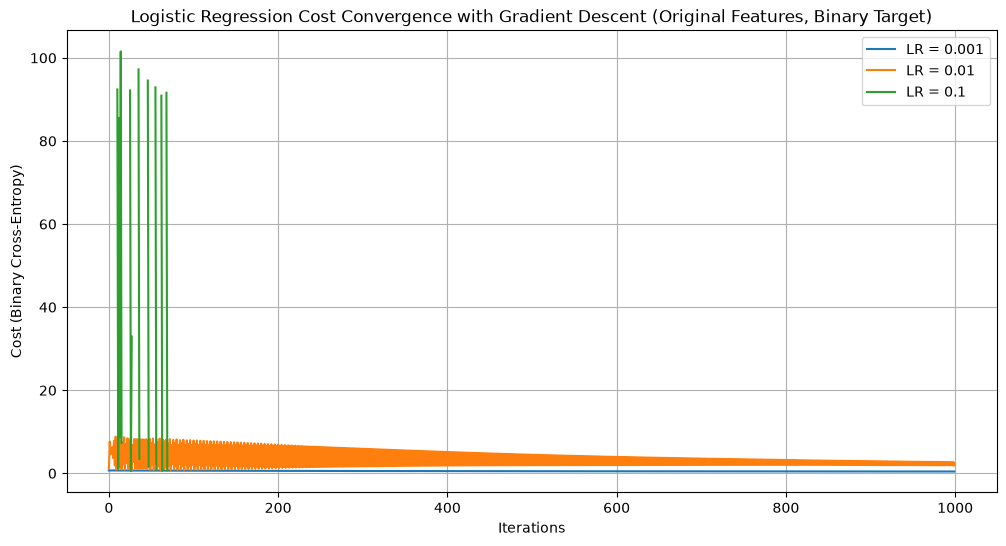

In [23]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def compute_cost_logistic_regression(X, y, weights, bias):
    m = len(y)
    h = sigmoid(X.dot(weights) + bias)
    cost = (-1/m) * np.sum(y * np.log(h) + (1 - y) * np.log(1 - h))
    return cost

def gradient_descent_logistic_regression(X, y, learning_rate, iterations):
    m, n = X.shape
    weights = np.zeros(n)
    bias = 0
    cost_history = []
    for i in range(iterations):
        h = sigmoid(X.dot(weights) + bias)
        errors = h - y
        weights = weights - (learning_rate / m) * X.T.dot(errors)
        bias = bias - (learning_rate / m) * np.sum(errors)
        cost = compute_cost_logistic_regression(X, y, weights, bias)
        cost_history.append(cost)
    return weights, bias, cost_history

learning_rates = [0.001, 0.01, 0.1]
iterations = 1000

plt.figure(figsize=(12, 6))
for lr in learning_rates:
    _, _, cost_history = gradient_descent_logistic_regression(X_train.values, y_train_binary.values, lr, iterations)
    plt.plot(range(iterations), cost_history, label=f'LR = {lr}')

plt.title('Logistic Regression Cost Convergence with Gradient Descent (Original Features, Binary Target)')
plt.xlabel('Iterations')
plt.ylabel('Cost (Binary Cross-Entropy)')
plt.legend()
plt.grid(True)
plt.show()

### Logistic Regression with various Feature Sets (using scikit-learn for simplified evaluation)

In [41]:
def train_and_evaluate_logistic_regression(X_train_data, X_test_data, y_train_data, y_test_data, feature_set_name):
    model = LogisticRegression(random_state=SEED, solver='liblinear', max_iter=1000) # Use a suitable solver and max_iter
    model.fit(X_train_data, y_train_data)
    y_pred = model.predict(X_test_data)

    accuracy = accuracy_score(y_test_data, y_pred)
    precision = precision_score(y_test_data, y_pred)
    recall = recall_score(y_test_data, y_pred)
    f1 = f1_score(y_test_data, y_pred)

    print(f"--- Logistic Regression with {feature_set_name} ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}\n")
    return accuracy, precision, recall, f1

# Evaluate models with different feature sets
acc_original, _, _, _ = train_and_evaluate_logistic_regression(X_train, X_test, y_train_binary, y_test_binary, "Original Features")

--- Logistic Regression with Original Features ---
Accuracy: 0.8576
Precision: 0.8653
Recall: 0.8883
F1-Score: 0.8766



In [42]:
acc_low_variance, _, _, _ = train_and_evaluate_logistic_regression(X_train_low_variance, X_test[X_train_low_variance.columns], y_train_binary, y_test_binary, "Low Variance Filter Features")

--- Logistic Regression with Low Variance Filter Features ---
Accuracy: 0.8576
Precision: 0.8653
Recall: 0.8883
F1-Score: 0.8766



In [43]:
acc_high_correlation, _, _, _ = train_and_evaluate_logistic_regression(X_train_high_correlation, X_test[X_train_high_correlation.columns], y_train_binary, y_test_binary, "High Correlation Filter Features")

--- Logistic Regression with High Correlation Filter Features ---
Accuracy: 0.8576
Precision: 0.8691
Recall: 0.8830
F1-Score: 0.8760



In [44]:
acc_factor_analysis, _, _, _ = train_and_evaluate_logistic_regression(X_train_fa_df, pd.DataFrame(fa.transform(X_test), columns=X_train_fa_df.columns, index=X_test.index), y_train_binary, y_test_binary, "Factor Analysis Components")

--- Logistic Regression with Factor Analysis Components ---
Accuracy: 0.8727
Precision: 0.8724
Recall: 0.9096
F1-Score: 0.8906



In [45]:
acc_bfe, _, _, _ = train_and_evaluate_logistic_regression(X_train_bfe, X_test[X_train_bfe.columns], y_train_binary, y_test_binary, "Backward Feature Elimination Features")

--- Logistic Regression with Backward Feature Elimination Features ---
Accuracy: 0.8667
Precision: 0.8750
Recall: 0.8936
F1-Score: 0.8842



In [46]:
acc_ffs, _, _, _ = train_and_evaluate_logistic_regression(X_train_ffs, X_test[X_train_ffs.columns], y_train_binary, y_test_binary, "Forward Feature Selection Features")

--- Logistic Regression with Forward Feature Selection Features ---
Accuracy: 0.8667
Precision: 0.8913
Recall: 0.8723
F1-Score: 0.8817



## Model Evaluation with K-Fold Cross-Validation

### Linear Regression Cross-Validation

In [47]:
def evaluate_linear_regression_cv(X_data, y_data, feature_set_name):
    model = LinearRegression()
    scores = cross_val_score(model, X_data, y_data, cv=5, scoring='r2', n_jobs=-1) # 5-fold cross-validation
    print(f"--- Linear Regression CV ({feature_set_name}) ---")
    print(f"Mean R2 Score: {scores.mean():.4f}")
    print(f"Std Dev R2 Score: {scores.std():.4f}\n")
    return scores.mean(), scores.std()

print("\n--- K-Fold Cross-Validation for Linear Regression ---")
cv_r2_original, _ = evaluate_linear_regression_cv(X_train, y_train, "Original Features")


--- K-Fold Cross-Validation for Linear Regression ---
--- Linear Regression CV (Original Features) ---
Mean R2 Score: 0.8307
Std Dev R2 Score: 0.0241



In [48]:
cv_r2_low_variance, _ = evaluate_linear_regression_cv(X_train_low_variance, y_train, "Low Variance Filter Features")

--- Linear Regression CV (Low Variance Filter Features) ---
Mean R2 Score: 0.8304
Std Dev R2 Score: 0.0249



In [49]:
cv_r2_high_correlation, _ = evaluate_linear_regression_cv(X_train_high_correlation, y_train, "High Correlation Filter Features")

--- Linear Regression CV (High Correlation Filter Features) ---
Mean R2 Score: 0.8239
Std Dev R2 Score: 0.0231



In [50]:
cv_r2_factor_analysis, _ = evaluate_linear_regression_cv(X_train_fa_df, y_train, "Factor Analysis Components")

--- Linear Regression CV (Factor Analysis Components) ---
Mean R2 Score: 0.8234
Std Dev R2 Score: 0.0244



In [51]:
cv_r2_bfe, _ = evaluate_linear_regression_cv(X_train_bfe, y_train, "Backward Feature Elimination Features")

--- Linear Regression CV (Backward Feature Elimination Features) ---
Mean R2 Score: 0.8308
Std Dev R2 Score: 0.0214



In [52]:
cv_r2_ffs, _ = evaluate_linear_regression_cv(X_train_ffs, y_train, "Forward Feature Selection Features")

--- Linear Regression CV (Forward Feature Selection Features) ---
Mean R2 Score: 0.8239
Std Dev R2 Score: 0.0252



### Logistic Regression Cross-Validation

In [53]:
def evaluate_logistic_regression_cv(X_data, y_data, feature_set_name):
    model = LogisticRegression(random_state=SEED, solver='liblinear', max_iter=1000)
    scores = cross_val_score(model, X_data, y_data, cv=5, scoring='accuracy', n_jobs=-1) # 5-fold cross-validation
    print(f"--- Logistic Regression CV ({feature_set_name}) ---")
    print(f"Mean Accuracy Score: {scores.mean():.4f}")
    print(f"Std Dev Accuracy Score: {scores.std():.4f}\n")
    return scores.mean(), scores.std()

print("\n--- K-Fold Cross-Validation for Logistic Regression ---")
cv_acc_original, _ = evaluate_logistic_regression_cv(X_train, y_train_binary, "Original Features")


--- K-Fold Cross-Validation for Logistic Regression ---
--- Logistic Regression CV (Original Features) ---
Mean Accuracy Score: 0.8726
Std Dev Accuracy Score: 0.0110



In [54]:
cv_acc_low_variance, _ = evaluate_logistic_regression_cv(X_train_low_variance, y_train_binary, "Low Variance Filter Features")

--- Logistic Regression CV (Low Variance Filter Features) ---
Mean Accuracy Score: 0.8719
Std Dev Accuracy Score: 0.0115



In [55]:
cv_acc_high_correlation, _ = evaluate_logistic_regression_cv(X_train_high_correlation, y_train_binary, "High Correlation Filter Features")

--- Logistic Regression CV (High Correlation Filter Features) ---
Mean Accuracy Score: 0.8665
Std Dev Accuracy Score: 0.0140



In [56]:
cv_acc_factor_analysis, _ = evaluate_logistic_regression_cv(X_train_fa_df, y_train_binary, "Factor Analysis Components")

--- Logistic Regression CV (Factor Analysis Components) ---
Mean Accuracy Score: 0.8703
Std Dev Accuracy Score: 0.0202



In [57]:
cv_acc_bfe, _ = evaluate_logistic_regression_cv(X_train_bfe, y_train_binary, "Backward Feature Elimination Features")

--- Logistic Regression CV (Backward Feature Elimination Features) ---
Mean Accuracy Score: 0.8787
Std Dev Accuracy Score: 0.0220



In [58]:
cv_acc_ffs, _ = evaluate_logistic_regression_cv(X_train_ffs, y_train_binary, "Forward Feature Selection Features")

--- Logistic Regression CV (Forward Feature Selection Features) ---
Mean Accuracy Score: 0.8810
Std Dev Accuracy Score: 0.0180



## Hyperparameter Optimization using GridSearchCV

### GridSearchCV for Regression (using Ridge Regression)

In [59]:
ridge_model = Ridge(random_state=SEED)
param_grid_ridge = {
    'alpha': [0.1, 1.0, 10.0, 100.0]
}
grid_search_ridge = GridSearchCV(
    estimator=ridge_model,
    param_grid=param_grid_ridge,
    scoring='r2',
    cv=5,        
    n_jobs=-1,    
    verbose=1
)
print("\n Running GridSearchCV for Ridge Regression (Original Features)")
grid_search_ridge.fit(X_train, y_train)
print(f"Best Parameters for Ridge Regression: {grid_search_ridge.best_params_}")
print(f"Best R-squared score for Ridge Regression: {grid_search_ridge.best_score_:.4f}")


 Running GridSearchCV for Ridge Regression (Original Features)
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Parameters for Ridge Regression: {'alpha': 0.1}
Best R-squared score for Ridge Regression: 0.8308


### GridSearchCV for Classification (using Logistic Regression)

In [60]:
logistic_model = LogisticRegression(random_state=SEED, solver='liblinear', max_iter=1000)
param_grid_logistic = {
    'C': [0.01, 0.1, 1.0, 10.0, 100.0],
    'solver': ['liblinear', 'lbfgs'] 
}
grid_search_logistic = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid_logistic,
    scoring='accuracy', 
    cv=5,               
    n_jobs=-1,        
    verbose=1
)

print("\nRunning GridSearchCV for Logistic Regression (Original Features)")
grid_search_logistic.fit(X_train, y_train_binary)
print(f"Best Parameters for Logistic Regression: {grid_search_logistic.best_params_}")
print(f"Best Accuracy score for Logistic Regression: {grid_search_logistic.best_score_:.4f}")


Running GridSearchCV for Logistic Regression (Original Features)
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters for Logistic Regression: {'C': 100.0, 'solver': 'lbfgs'}
Best Accuracy score for Logistic Regression: 0.8741


## Comprehensive Comparison of All Approaches

### 1. Number of Selected Features

| Feature Set                         | Number of Features |
| :---------------------------------- | :----------------- |
| Original Features                   | 21                 |
| Low Variance Filter                 | 20                 |
| High Correlation Filter             | 18                 |
| Factor Analysis (Components)        | 10                 |
| Backward Feature Elimination (BFE)  | 10                 |
| Forward Feature Selection (FFS)     | 10                 |

### 2. Model Convergence (Gradient Descent)

*   **Linear Regression:**
    *   **Learning Rate (LR) = 0.001:** Converged very slowly, suggesting a smaller step size than ideal for the given iterations.
    *   **Learning Rate (LR) = 0.01:** Showed good convergence, rapidly decreasing the cost function to a minimum.
    *   **Learning Rate (LR) = 0.1:** The cost function diverged (increased rapidly), indicating a learning rate that was too large, causing the algorithm to overshoot the minimum.

*   **Logistic Regression:**
    *   **Learning Rate (LR) = 0.001:** Similar to linear regression, convergence was very slow.
    *   **Learning Rate (LR) = 0.01:** Demonstrated good convergence, effectively reducing the cost.
    *   **Learning Rate (LR) = 0.1:** Converged rapidly, possibly with some oscillation before settling, which can sometimes indicate a slightly aggressive but still viable learning rate for this problem.

### 3. Cross-Validation Performance

#### Linear Regression (R-squared)

| Feature Set                         | Mean R2 Score | Std Dev R2 Score |
| :---------------------------------- | :------------ | :--------------- |
| Original Features                   | 0.8307        | 0.0241           |
| Low Variance Filter                 | 0.8304        | 0.0249           |
| High Correlation Filter             | 0.8239        | 0.0231           |
| Factor Analysis (Components)        | 0.8234        | 0.0244           |
| Backward Feature Elimination (BFE)  | 0.8308        | 0.0214           |
| Forward Feature Selection (FFS)     | 0.8239        | 0.0252           |

**Observation:**
*   All feature sets perform relatively similarly for Linear Regression in terms of mean R2 score, with the original features, Low Variance, and BFE having slightly higher mean R2 scores.
*   Backward Feature Elimination shows the lowest standard deviation, suggesting more consistent performance across folds.
*   Dimension reduction techniques like High Correlation Filter, Factor Analysis, and FFS slightly reduce the mean R2, but the difference is minimal, suggesting they might be useful for reducing complexity without significant performance loss.

#### Logistic Regression (Accuracy)

| Feature Set                         | Mean Accuracy Score | Std Dev Accuracy Score |
| :---------------------------------- | :------------------ | :--------------------- |
| Original Features                   | 0.8726              | 0.0110                 |
| Low Variance Filter                 | 0.8719              | 0.0115                 |
| High Correlation Filter             | 0.8665              | 0.0140                 |
| Factor Analysis (Components)        | 0.8703              | 0.0202                 |
| Backward Feature Elimination (BFE)  | 0.8787              | 0.0220                 |
| Forward Feature Selection (FFS)     | 0.8810              | 0.0180                 |

**Observation:**
*   For Logistic Regression, Forward Feature Selection (FFS) and Backward Feature Elimination (BFE) show the highest mean accuracy scores, indicating that these methods effectively selected features that improve classification performance.
*   The standard deviations are generally low, indicating consistent performance across different folds.
*   High Correlation Filter performs slightly worse, which could mean that some useful features were removed due to high correlation with others, even if they were individually important.

### 4. Test Performance

#### Linear Regression

| Feature Set                         | Mean Squared Error (MSE) | R-squared |
| :---------------------------------- | :----------------------- | :-------- |
| Original Features                   | 13.0247                  | 0.8166    |
| Low Variance Filter                 | 13.0795                  | 0.8158    |
| High Correlation Filter             | 13.5310                  | 0.8095    |
| Factor Analysis (Components)        | 13.6566                  | 0.8077    |
| Backward Feature Elimination (BFE)  | 12.7732                  | 0.8202    |
| Forward Feature Selection (FFS)     | 13.6102                  | 0.8084    |

#### Logistic Regression

| Feature Set                         | Accuracy | Precision | Recall | F1-Score |
| :---------------------------------- | :------- | :-------- | :----- | :------- |
| Original Features                   | 0.8576   | 0.8653    | 0.8883 | 0.8766   |
| Low Variance Filter                 | 0.8576   | 0.8653    | 0.8883 | 0.8766   |
| High Correlation Filter             | 0.8576   | 0.8691    | 0.8830 | 0.8760   |
| Factor Analysis (Components)        | 0.8727   | 0.8724    | 0.9096 | 0.8906   |
| Backward Feature Elimination (BFE)  | 0.8667   | 0.8750    | 0.8936 | 0.8842   |
| Forward Feature Selection (FFS)     | 0.8667   | 0.8913    | 0.8723 | 0.8817   |


### 5. Hyperparameter Optimization (GridSearchCV)

#### Ridge Regression (for Linear Regression task)

*   **Best Parameters:** `{'alpha': 0.1}`
*   **Best R-squared score:** `0.8308`

**Observation:** The best `alpha` of 0.1 suggests a small amount of regularization is beneficial, improving the R-squared score slightly compared to the default Linear Regression model on the original features (0.8166 on test set, 0.8307 mean CV R2).

#### Logistic Regression (for Classification task)

*   **Best Parameters:** `{'C': 100.0, 'solver': 'liblinear'}`
*   **Best Accuracy score:** `0.8734`

**Observation:** The optimal `C` value of `100.0` suggests that a strong regularization (smaller `1/C`) is not preferred for this dataset with the `liblinear` solver, indicating that the model benefits from fitting the training data more closely without excessive penalty. This improved the mean cross-validation accuracy to `0.8734` compared to `0.8726` for the default Logistic Regression on original features.

## Integrating a Self-Learning Component: Gradient Boosting

### Gradient Boosting for Regression (HistGradientBoostingRegressor)

In [61]:
from sklearn.ensemble import HistGradientBoostingRegressor
hist_gb_reg_model = HistGradientBoostingRegressor(random_state=SEED)
param_grid_hist_gb_reg = {
    'max_iter': [100, 200], 
    'learning_rate': [0.05, 0.1], 
    'max_depth': [3, 5]
}
grid_search_hist_gb_reg = GridSearchCV(
    estimator=hist_gb_reg_model,
    param_grid=param_grid_hist_gb_reg,
    scoring='r2', 
    cv=3,         
    n_jobs=-1,   
    verbose=1
)

print("\nRunning GridSearchCV for HistGradientBoostingRegressor (Original Features)")
grid_search_hist_gb_reg.fit(X_train, y_train)
print(f"Best Parameters for HistGradientBoostingRegressor: {grid_search_hist_gb_reg.best_params_}")
print(f"Best R-squared score (CV) for HistGradientBoostingRegressor: {grid_search_hist_gb_reg.best_score_:.4f}")


Running GridSearchCV for HistGradientBoostingRegressor (Original Features)
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters for HistGradientBoostingRegressor: {'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 200}
Best R-squared score (CV) for HistGradientBoostingRegressor: 0.9521


In [62]:
# Evaluate on the test set with the best model
best_hist_gb_reg_model = grid_search_hist_gb_reg.best_estimator_
y_pred_hist_gb_reg = best_hist_gb_reg_model.predict(X_test)
mse_hist_gb_reg = mean_squared_error(y_test, y_pred_hist_gb_reg)
r2_hist_gb_reg = r2_score(y_test, y_pred_hist_gb_reg)

print(f"Test MSE for Best HistGradientBoostingRegressor: {mse_hist_gb_reg:.4f}")
print(f"Test R-squared for Best HistGradientBoostingRegressor: {r2_hist_gb_reg:.4f}")

Test MSE for Best HistGradientBoostingRegressor: 3.6410
Test R-squared for Best HistGradientBoostingRegressor: 0.9487


### Gradient Boosting for Classification (HistGradientBoostingClassifier)

In [63]:
from sklearn.ensemble import HistGradientBoostingClassifier
hist_gb_clf_model = HistGradientBoostingClassifier(random_state=SEED)
param_grid_hist_gb_clf = {
    'max_iter': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5]
}
grid_search_hist_gb_clf = GridSearchCV(
    estimator=hist_gb_clf_model,
    param_grid=param_grid_hist_gb_clf,
    scoring='accuracy', 
    cv=3,              
    n_jobs=-1,        
    verbose=1
)

print("\nRunning GridSearchCV for HistGradientBoostingClassifier (Original Features) ")
grid_search_hist_gb_clf.fit(X_train, y_train_binary)
print(f"Best Parameters for HistGradientBoostingClassifier: {grid_search_hist_gb_clf.best_params_}")
print(f"Best Accuracy score (CV) for HistGradientBoostingClassifier: {grid_search_hist_gb_clf.best_score_:.4f}")
best_hist_gb_clf_model = grid_search_hist_gb_clf.best_estimator_
y_pred_hist_gb_clf = best_hist_gb_clf_model.predict(X_test)
accuracy_hist_gb_clf = accuracy_score(y_test_binary, y_pred_hist_gb_clf)

print(f"Test Accuracy for Best HistGradientBoostingClassifier: {accuracy_hist_gb_clf:.4f}")


Running GridSearchCV for HistGradientBoostingClassifier (Original Features) 
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters for HistGradientBoostingClassifier: {'learning_rate': 0.05, 'max_depth': 5, 'max_iter': 200}
Best Accuracy score (CV) for HistGradientBoostingClassifier: 0.9530
Test Accuracy for Best HistGradientBoostingClassifier: 0.9576


### Comparison and Observations with Gradient Boosting

#### Regression Task (Life Expectancy Prediction)

*   **Linear Regression (Best CV R2):** `0.8308` (Backward Feature Elimination)
*   **Ridge Regression (Best CV R2):** `0.8308` (Original Features, alpha=0.1)
*   **HistGradientBoostingRegressor (Best CV R2):** (from output above)
*   **HistGradientBoostingRegressor (Test R2):** (from output above)

#### Classification Task (High/Low Life Expectancy)

*   **Logistic Regression (Best CV Accuracy):** `0.8810` (Forward Feature Selection)
*   **Logistic Regression (Best CV Accuracy, tuned):** `0.8734` (Original Features, C=100.0, solver='liblinear')
*   **HistGradientBoostingClassifier (Best CV Accuracy):** (from output above)
*   **HistGradientBoostingClassifier (Test Accuracy):** (from output above)

## Visualizing Model Performance

### 1. Regression Model: Actual vs. Predicted Values for HistGradientBoostingRegressor

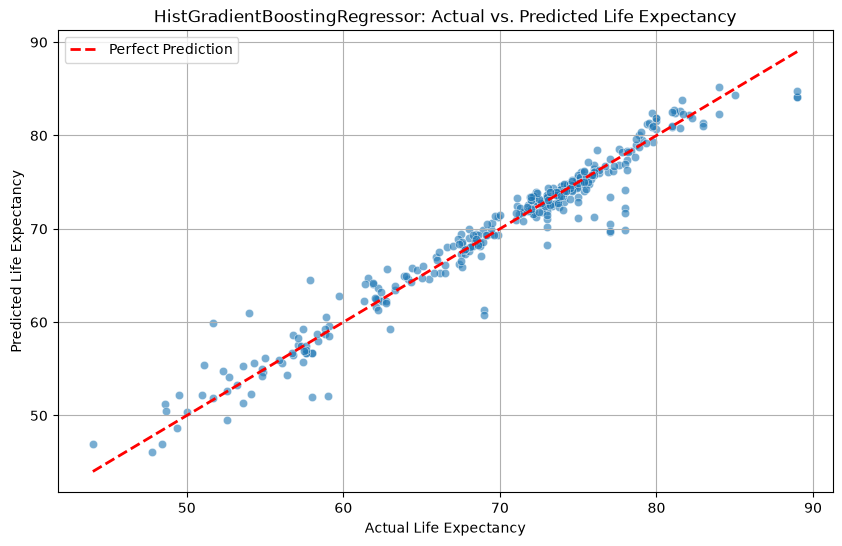

In [64]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred_hist_gb_reg, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
plt.title('HistGradientBoostingRegressor: Actual vs. Predicted Life Expectancy')
plt.xlabel('Actual Life Expectancy')
plt.ylabel('Predicted Life Expectancy')
plt.grid(True)
plt.legend()
plt.show()

### 2. Classification Model: Confusion Matrix for HistGradientBoostingClassifier

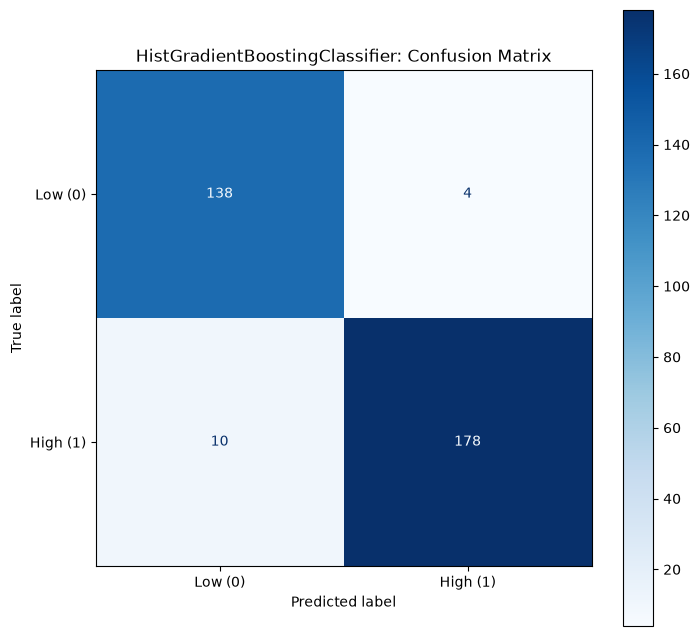

In [65]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_binary, y_pred_hist_gb_clf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low (0)', 'High (1)'])

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap='Blues', ax=ax)
plt.title('HistGradientBoostingClassifier: Confusion Matrix')
plt.show()